# 02 · Motor de simulación con SimPy (paso 12)

**Propósito.** Construir y **verificar** el motor que simula los dos cruces de la Séptima Avenida (W30 y W29) con el tramo de ≈ 80 m entre ellos. Una obstrucción reduce la capacidad de salida del tramo. Comparamos cómo responden las estrategias A, B y C.

Este notebook **no** saca conclusiones del experimento: corre **una sola réplica** para mostrar que el motor funciona y pasa sus verificaciones. La comparación con réplicas, intervalos de confianza y varias duraciones de la obstrucción es el paso 13.

> **Advertencia de honestidad.** La demanda viene de la base ficticia, y los tiempos de semáforo, carriles y capacidades son **supuestos declarados** (tabla de la sección 1). Los números ilustran el mecanismo, no el tráfico real.

El código del motor está en `src/motor_simpy.py` y sus pruebas automáticas, en `tests/test_motor_simpy.py`.

## Cómo estudiar este cuaderno

Lee en orden: **explicación → datos que entran → operaciones → código → salida → interpretación**. Las guías añadidas describen la celda inmediatamente siguiente.

Si solo quieres estudiar, puedes leer las salidas guardadas. Para reproducir, activa el entorno del proyecto, abre este notebook y usa **Restart Kernel and Run All Cells**. Respeta los archivos de entrada que se nombran en cada sección y el orden 01_datos → 01c → 01d → 02 → 03 para recorrer el trabajo científico.

Los ejemplos marcados como didácticos explican un cálculo y no son nuevas mediciones de NYC. Las salidas existentes corresponden a ejecuciones anteriores; esta revisión didáctica conserva el código y esas salidas.


## 0. Cómo funciona el motor, en palabras

**Analogía.** Imagina cuatro filas de un supermercado (los accesos) y un pasillo angosto con lugar para 33 carritos (el tramo W30→W29).

- **Accesos:** Séptima hacia el sur en W30 (`N`), W30 hacia el este (`W30O`), el tramo al llegar a W29 (`T`) y W29 hacia el oeste (`W29E`).
- **Descarga:** cada fila deja pasar un vehículo cada *h* segundos, pero solo mientras su semáforo está en verde. Con 1,800 veh/h por carril y 3 carriles, *h* = 3600 / (1800 × 3) ≈ 0.67 s. Un camión o un autobús tarda 1.5 veces más.
- **Espacio en el tramo:** quien va hacia el tramo solo puede cruzar W30 si hay lugar (ocupación < K = 33). Si no hay, **espera en la línea de alto sin bloquear el cruce** y detiene a todos los que vienen detrás en la misma fila. Así se contagia la cola hacia W31: es el *spillback*.
- **Recorrido:** dentro del tramo, el vehículo tarda τ = 3.6 × 80 / 25 ≈ 11.5 s en llegar a W29 y luego hace fila allí.
- **Obstrucción:** durante *D* minutos, el tramo descarga en W29 por 1 carril en lugar de 3. **No se borra ningún vehículo.**

**SimPy** es un reloj de eventos: en lugar de avanzar segundo a segundo, salta al siguiente suceso (una llegada, una salida, un cambio de semáforo).

**Datos que entran.** CSV de intervalos y vehículos, más funciones del motor en `src/`.

**Operaciones, en orden.** Ubica el proyecto → importa el mismo motor que usan las pruebas → carga tablas → muestra versión SimPy.

**Qué debes revisar en la salida.** El notebook organiza y explica las corridas; la lógica de eventos está en `motor_simpy.py`.


In [1]:
# Importa bibliotecas para localizar los módulos del proyecto, hacer cálculos y sorteos
# numéricos, trabajar con tablas, dibujar las gráficas.
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt

# Importa herramientas para manejar carpetas y archivos.
from pathlib import Path

# Ubica la carpeta principal del proyecto para construir las rutas de los archivos.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Permite importar los módulos guardados en la carpeta src del proyecto.
sys.path.insert(0, str(RAIZ / "src"))

# Importa herramientas para usar parámetros, simulación y verificaciones del motor.
from motor_simpy import (
    Parametros,
    simular,
    llegadas_base,
    llegadas_constantes,
    verificar_conservacion,
    verificar_little,
    webster,
    grado_saturacion,
)

# Importa bibliotecas para consultar la biblioteca del motor de eventos.
import simpy

# Lee la tabla de intervalos del archivo CSV.
iv = pd.read_csv(RAIZ / "datos/procesados/intervalos.csv")

# Lee la tabla individual de vehículos desde el CSV.
vh = pd.read_csv(RAIZ / "datos/procesados/vehiculos.csv")

# Ajusta resolución y bordes de las gráficas.
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)

# Muestra en pantalla SimPy.
print("SimPy", simpy.__version__)


SimPy 4.1.2


**Lectura.** Las librerías y la base se cargan sin errores. El motor se importa desde `src/` para que el notebook y las pruebas usen exactamente el mismo código.

## 1. Parámetros: qué viene de datos y qué es supuesto

Requisito del plan: **parámetros trazables**. Cada valor dice de dónde sale.

**Datos que entran.** Valores predeterminados de `Parametros`.

**Operaciones, en orden.** Instancia parámetros → asigna etiquetas de procedencia → presenta tabla y K/τ derivados.

**Qué debes revisar en la salida.** Las etiquetas no verifican las fuentes. Verde, ciclo, carriles y velocidad deben defenderse como supuestos del experimento.


In [2]:
# Carga los valores predeterminados de la simulación.
p = Parametros()

# Relaciona los parámetros con sus etiquetas de procedencia.
fuente = {
    "ciclo": "supuesto (ciclo típico de Manhattan, ejemplo del diseño)",
    "verde_av": "supuesto",
    "verde_tr": "supuesto",
    "amarillo": "supuesto",
    "todo_rojo": "supuesto",
    "desfase_w30": "referencia (0)",
    "desfase_w29_indep": "supuesto A: elegido sin mirar el viaje; habrá sensibilidad en el paso 13",
    "carriles_av": "supuesto (avenida como almacén agregado)",
    "carriles_tr": "supuesto",
    "sat_carril": "supuesto (valor de manual, 1,800 veh/h verde)",
    "pce_pesado": "supuesto",
    "largo_tramo": "medido en el mapa (≈ 80 m)",
    "espacio_veh": "supuesto (7 m por vehículo detenido)",
    "v_libre_kmh": "supuesto (25 km/h, límite urbano)",
    "almacen_cuadra_previa": "supuesto (igual al tramo)",
    "frac_H": "supuesto C (sensibilidad pendiente)",
    "frac_L": "supuesto C",
    "verde_min": "supuesto C",
    "despeje": "supuesto C",
    "carriles_bloqueados": "supuesto (severidad de la obstrucción)",
}

# Reúne nombre, valor y procedencia declarada de cada parámetro.
tab = pd.DataFrame(
    [(k, v, fuente.get(k, "control de la simulación")) for k, v in vars(p).items()],
    columns=["parámetro", "valor", "fuente"],
)

# Muestra en pantalla el mensaje y los valores calculados.
print(
    f"Derivados: K = {p.K} vehículos, τ = {p.tau:.1f} s, desfase W29 en B y C = {Parametros(estrategia='B').desfase_w29:.0f} s"
)

# Muestra la tabla tab con sus valores calculados.
tab


Derivados: K = 33 vehículos, τ = 11.5 s, desfase W29 en B y C = 12 s


,parámetro,valor,fuente
0,estrategia,A,control de la simulación
1,ciclo,60.0,"supuesto (ciclo típico de Manhattan, ejemplo d..."
2,verde_av,28.0,supuesto
3,verde_tr,22.0,supuesto
4,amarillo,3.0,supuesto
5,todo_rojo,2.0,supuesto
6,desfase_w30,0.0,referencia (0)
7,desfase_w29_indep,40.0,supuesto A: elegido sin mirar el viaje; habrá ...
8,carriles_av,3,supuesto (avenida como almacén agregado)
9,carriles_tr,1,supuesto


**Lectura.** Solo el largo del tramo sale de una medición, y la demanda sale de la base ficticia. Todo lo demás es supuesto. Por eso el paso 13 debe incluir pruebas de sensibilidad, por lo menos para el desfase de A, los umbrales de C y la severidad de la obstrucción.

## 2. ¿Alcanza la capacidad en condiciones normales? (ρ < 1)

**Grado de saturación** ρ = demanda / capacidad, con capacidad = 1,800 × carriles × verde / ciclo. Si ρ ≥ 1, la cola crecería sin obstrucción y no podríamos atribuirle nada a ella. Usamos la **tasa máxima de toda la semana** (el peor caso), contando los vehículos pesados como 1.5 autos.

### Capacidad y saturación con unidades

`s` es descarga de saturación en veh-equivalentes/h de verde por carril; `n` es número de carriles; `g` es verde en segundos; `c` es ciclo en segundos. La capacidad media aproximada es `C = s × n × g/c` en veh-equivalentes/h. `ρ = q/C` compara demanda q con esa capacidad.

Con s = 1,800, n = 3, g = 28 s y c = 60 s: `C = 1,800 × 3 × 28/60 = 2,520 veh-eq/h`. Si quedan uno de tres carriles: `C = 840 veh-eq/h`.

Ejemplo didáctico q = 1,000 veh-eq/h: `ρ = 1,000/2,520 ≈ 0.40` normal y `ρ = 1,000/840 ≈ 1.19` obstruido. Son aproximaciones de servicio, no vehículos garantizados por hora. Un ρ menor que uno no impide colas durante el rojo ni garantiza vaciar la cola en cada ciclo.


**Datos que entran.** Máximos de tasa y proporciones en la base.

**Operaciones, en orden.** Convierte pesados a vehículos equivalentes → calcula demanda hacia el tramo → divide demanda por capacidad normal y obstruida.

**Qué debes revisar en la salida.** Combina máximos que pueden no coincidir; es una comprobación conservadora, no la trayectoria de una corrida.


In [3]:
# Obtiene los máximos de tasa y proporciones por acceso.
pico = iv.groupby("acceso_id")[
    ["tasa_llegada_vph", "prop_hacia_tramo", "prop_pesados"]
].max()

# Define cómo convertir la tasa a vehículos equivalentes contando más peso a los
# pesados.
f = lambda a: pico.loc[a, "tasa_llegada_vph"] * (1 + 0.5 * pico.loc[a, "prop_pesados"])

# Suma la demanda equivalente que entra al tramo desde Séptima y W30.
q_tramo = (
    f(33804) * pico.loc[33804, "prop_hacia_tramo"]
    + f(33803) * pico.loc[33803, "prop_hacia_tramo"]
)

# Reúne demanda y saturación de cada acceso en condiciones normales y obstruidas.
rho = pd.DataFrame(
    {
        "demanda_pico (veh-eq/h)": [f(33804), f(33803), f(33894), q_tramo, q_tramo],
        "ρ": [
            grado_saturacion(f(33804), p, "av"),
            grado_saturacion(f(33803), p, "tr"),
            grado_saturacion(f(33894), p, "tr"),
            grado_saturacion(q_tramo, p, "av"),
            grado_saturacion(
                q_tramo, p, "av", carriles=p.carriles_av - p.carriles_bloqueados
            ),
        ],
    },
    index=[
        "Séptima en W30",
        "W30 EB",
        "W29 WB",
        "Tramo en W29 (normal)",
        "Tramo en W29 (OBSTRUIDO)",
    ],
).round(2)

# Muestra la tabla rho con sus valores calculados.
rho


,demanda_pico (veh-eq/h),ρ
Séptima en W30,1600.97,0.64
W30 EB,424.42,0.64
W29 WB,472.23,0.72
Tramo en W29 (normal),1632.20,0.65
Tramo en W29 (OBSTRUIDO),1632.20,1.94


**Lectura.** Los cocientes normales están por debajo de uno: la capacidad media calculada supera la demanda aproximada. Esto no impide colas transitorias ni garantiza vaciado en cada ciclo. Con la obstrucción el cociente supera uno: si esa demanda persiste, tiende a acumularse tráfico. La comprobación combina máximos que pueden no ocurrir juntos.

## 3. Escenario de demostración

- **Día:** miércoles 2026-03-04 (sin lluvia ni evento), de 16:30 a 18:30. Usamos los vehículos **exactos** de la tabla `vehiculos`, iguales para A, B y C.
- **Calentamiento:** los primeros 15 minutos no se cuentan, porque el sistema empieza vacío.
- **Obstrucción:** a las 17:00 (t = 1,800 s), durante 10 minutos.
- **Vaciado:** se simulan 30 minutos extra sin llegadas nuevas, para que todos salgan.

**Datos que entran.** Vehículos exactos del miércoles 16:30–18:30.

**Operaciones, en orden.** Filtra llegadas → simula A/B/C con las mismas entradas → excluye calentamiento en métricas → reúne tabla.

**Qué debes revisar en la salida.** Una corrida por estrategia ilustra el funcionamiento. Las réplicas nuevas y su incertidumbre se estudian en `03_resultados`.


In [4]:
# Selecciona los vehículos de la base que llegan el miércoles entre 16:30 y 18:30.
ll = llegadas_base(iv, vh, "2026-03-04", "16:30", "18:30")

# Fija 9,000 s de simulación total y 900 s de calentamiento.
HORIZONTE, CALENT = (7200 + 1800, 900)

# Simula A, B y C con los mismos vehículos y conserva cada corrida.
res = {
    e: simular(
        Parametros(estrategia=e, obstr_inicio=1800, obstr_dur=600), ll, HORIZONTE
    )
    for e in "ABC"
}

# Extrae las métricas de las corridas y usa la estrategia como índice.
tabla = pd.DataFrame([r.metricas(desde=CALENT) for r in res.values()]).set_index(
    "estrategia"
)

# Muestra en pantalla vehículos simulados.
print("vehículos simulados:", len(ll), ll["acceso"].value_counts().to_dict())

# Muestra la tabla transpuesta, intercambiando filas y columnas.
tabla.round(1).T


vehículos simulados: 4115 {'N': 2558, 'W29E': 856, 'W30O': 701}


estrategia,A,B,C
vehiculos,3653.0,3653.0,3653.0
completados,3653.0,3653.0,3653.0
pendientes_al_cierre,0.0,0.0,0.0
espera_media_s,35.9,23.0,24.8
espera_p95_s,103.8,75.4,99.3
ocupacion_max_tramo,33.0,33.0,27.0
cola_max_septima,58.0,48.0,75.0
cola_max_w30,12.0,12.0,12.0
s_cola_llega_w31,300.0,170.0,425.0
s_bloqueo_w30,120.0,130.0,0.0


**Lectura (una sola réplica, sin conclusiones).**

- **B frente a A:** coordinar el desfase reduce mucho la espera media, sobre todo en la Séptima. Los carros encuentran verde en W29 al terminar el tramo.
- **Con la obstrucción:** en A y B el tramo llega a 33 de 33 y la cola de la Séptima alcanza W31 (`s_cola_llega_w31` > 0). B lo hace durante menos tiempo, porque empieza con el tramo más vacío. Es la idea de A16: la coordinación da margen.
- **C frente a B:** C impide el bloqueo físico de W30 (`s_bloqueo_w30` = 0) y nunca deja que el tramo se llene. A cambio, retiene a la Séptima antes: su cola es más larga y llega a W31 durante más tiempo. Con estos umbrales, C **traslada** la cola hacia arriba en lugar de reducirla. Si eso se mantiene con réplicas y otros umbrales, es un resultado, no un error.

## 4. ¿Qué pasa en el tiempo?

Ocupación del tramo (arriba) y cola de la Séptima esperando en W30 (abajo). La franja gris marca la obstrucción y la línea punteada, el almacenamiento de la cuadra anterior: por encima de ella, la cola llega a W31.

**Datos que entran.** Series temporales de esas tres corridas.

**Operaciones, en orden.** Recorta ventana → convierte segundos a minutos → dibuja ocupación/cola → marca incidente y capacidad.

**Qué debes revisar en la salida.** Arriba se cuenta gente dentro del tramo; abajo, vehículos esperando antes de W30. Son ubicaciones distintas.


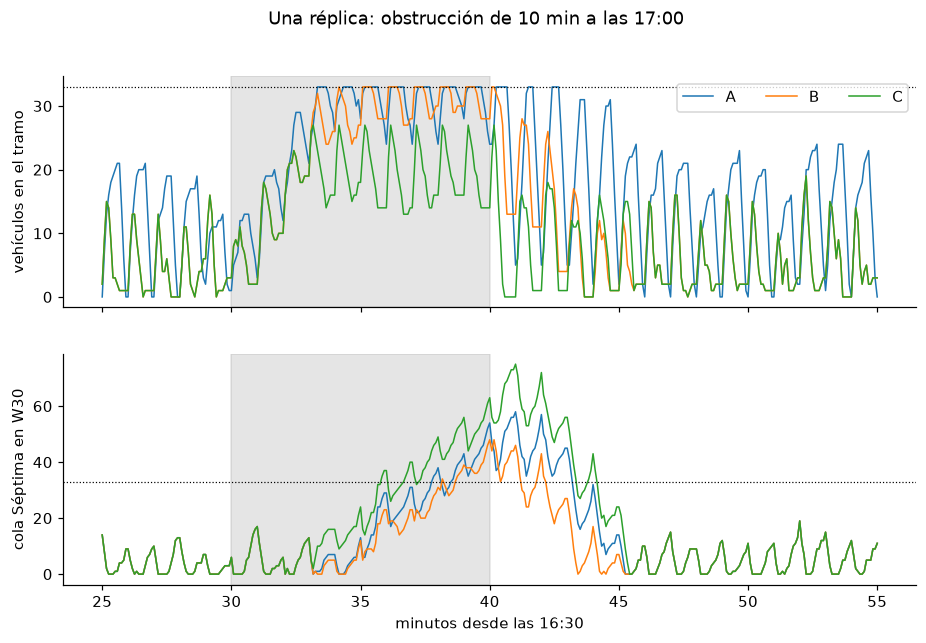

In [5]:
# Crea la figura y los paneles donde se dibujarán los gráficos.
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Recorre las corridas de A, B y C para dibujar sus series.
for e, r in res.items():
    # Recupera la serie temporal de esta corrida.
    s = r.serie

    # Marca las muestras entre los segundos 1,500 y 3,300 para ampliar la gráfica.
    m = (s.t >= 1500) & (s.t <= 3300)

    # Dibuja esta serie con los valores y el estilo indicados.
    ax[0].plot(s.t[m] / 60, s.n_tramo[m], label=e, lw=1)

    # Dibuja esta serie con los valores y el estilo indicados.
    ax[1].plot(s.t[m] / 60, s.cola_N[m], label=e, lw=1)

# Aplica el mismo ajuste a cada panel del gráfico.
for a in ax:
    # Sombrea el periodo de obstrucción entre los minutos 30 y 40.
    a.axvspan(30, 40, color="grey", alpha=0.2)

# Marca con una línea horizontal el valor de referencia indicado.
ax[0].axhline(p.K, color="k", ls=":", lw=0.8)

# Escribe la etiqueta del eje vertical y su unidad.
ax[0].set_ylabel("vehículos en el tramo")

# Muestra la leyenda que identifica las series.
ax[0].legend(ncol=3)

# Marca con una línea horizontal el valor de referencia indicado.
ax[1].axhline(p.almacen_cuadra_previa, color="k", ls=":", lw=0.8)

# Escribe la etiqueta del eje vertical y su unidad.
ax[1].set_ylabel("cola Séptima en W30")

# Escribe la etiqueta del eje horizontal.
ax[1].set_xlabel("minutos desde las 16:30")

# Escribe el título del gráfico.
fig.suptitle("Una réplica: obstrucción de 10 min a las 17:00")

# Muestra el gráfico terminado en la salida de esta celda.
plt.show()


**Lectura.** Antes de la obstrucción, B mantiene el tramo más vacío que A. Durante la obstrucción, A y B llegan al tope K y la cola de la Séptima sube por encima de la línea de W31. C se detiene cerca de su umbral H (≈ 26) y su cola crece más. Cuando termina la obstrucción, los tres se vacían en pocos minutos, en estas corridas; ρ < 1 por sí solo no garantiza ese tiempo de recuperación.

## 5. Bitácora del motor (estrategia C)

El motor anota cada suceso de control: inicio y fin de la obstrucción, encendido y apagado de la regulación, y cortes del verde. Sirve para auditar **por qué** pasó algo.

**Datos que entran.** Sucesos registrados por la estrategia C.

**Operaciones, en orden.** Convierte la bitácora en tabla → presenta doce sucesos.

**Qué debes revisar en la salida.** El tiempo es segundo simulado desde las 16:30. Busca activación/desactivación para explicar el cambio de control.


In [6]:
# Muestra las primeras filas sin alterar la tabla completa.
pd.DataFrame(res["C"].bitacora, columns=["t (s)", "suceso"]).head(12)


,t (s),suceso
0,1800.000000,obstrucción INICIA
1,1985.500000,C: regulación ON (ocupación 27/33)
2,1990.000000,C: corta verde de avenida en W30
3,2007.166667,C: regulación OFF (ocupación 19/33)
4,2047.500000,C: regulación ON (ocupación 27/33)
5,2050.000000,C: corta verde de avenida en W30
6,2067.166667,C: regulación OFF (ocupación 19/33)
7,2107.833333,C: regulación ON (ocupación 27/33)
8,2110.000000,C: corta verde de avenida en W30
9,2127.166667,C: regulación OFF (ocupación 19/33)


**Lectura.** La regulación se enciende al llegar a H = 0.8 × 33 ≈ 27 vehículos y se apaga al bajar a L = 0.6 × 33 ≈ 20. La distancia entre los dos umbrales (histéresis) evita que el semáforo cambie de decisión a cada segundo.

## 6. Verificaciones

1. **Conservación:** en cada instante, generados = salidos + dentro del sistema, y 0 ≤ ocupación ≤ K.
2. **Ley de Little** en el tramo: **L = λ · W**, es decir, ocupación media = (entradas por segundo) × (tiempo medio dentro). Analogía: si entran 2 personas por minuto a una tienda y cada una se queda 10 minutos, en promedio hay 20 adentro.
3. **Webster (1958):** para un acceso aislado con llegadas aleatorias existe una fórmula de la demora media:
$$d = \frac{c(1-g/c)^2}{2(1-(g/c)\,x)} + \frac{x^2}{2q(1-x)} - 0.65\left(\frac{c}{q^2}\right)^{1/3} x^{2+5g/c}$$
con *c* el ciclo, *g* el verde, *q* la llegada (veh/s) y *x* = ρ. Simulamos 10 horas de W29 WB con 500 veh/h y comparamos.

### Qué comprueba cada identidad

**Conservación.** Si había 10 vehículos, entran 6 y salen 4, quedan `10+6−4 = 12`. Para el sistema completo: generados = salidos + aún dentro. Es una condición contable que debe cumplirse aunque haya congestión.

**Little.** L es ocupación media (vehículos), λ es flujo medio (veh/s) y W es permanencia media (s): `L = λW`. Ejemplo: 0.2 veh/s × 20 s = 4 vehículos. Deben coincidir sistema, población y periodo. En horizontes finitos importan los vehículos presentes en los extremos y el método de integración; se usa como comprobación aproximada.

**Webster.** En la fórmula anterior, c y g se miden en segundos, q en veh/s y x es adimensional; d resulta en segundos por vehículo. Cada término aproxima una parte de la demora en condiciones de aplicación concretas. Aquí el ensayo se hace en un acceso aislado y subcrítico; no se aplica como solución exacta del corredor con bloqueo.


**Datos que entran.** Corridas A/B/C y un ensayo separado de W29.

**Operaciones, en orden.** Simula el ensayo largo → contrasta demora con Webster → revisa Little, conservación y salidas finales.

**Qué debes revisar en la salida.** Cada comprobación tiene sus supuestos; un acuerdo aproximado no acredita calibración con tráfico real.


In [7]:
# Simula W29 con 500 veh/h durante diez horas y tiempo adicional para vaciar.
r_web = simular(Parametros(), llegadas_constantes("W29E", 500, 36000, semilla=1), 37000)

# Calcula demora media simulada y la aproximación de Webster.
d_sim, d_web = (r_web.tiempos()["espera"].mean(), webster(500, Parametros()))

# Comprueba la relación de Little en cada una de las estrategias.
lit = {e: verificar_little(r) for e, r in res.items()}

# Reúne los valores calculados en una tabla para mostrarlos.
pd.DataFrame(
    {
        "resultado": [
            all((verificar_conservacion(r) for r in res.values())),
            ", ".join((f"{e}: {v['error_rel']:.1%}" for e, v in lit.items())),
            f"simulada {d_sim:.1f} s vs Webster {d_web:.1f} s ({d_sim / d_web - 1:+.0%})",
            all((r.veh["t_salida"].notna().all() for r in res.values())),
        ]
    },
    index=[
        "Conservación y cotas (A, B, C)",
        "Little: error relativo",
        "Webster (W29 WB, 500 veh/h)",
        "Todos los vehículos salen al final",
    ],
)


,resultado
"Conservación y cotas (A, B, C)",True
Little: error relativo,"A: 0.0%, B: 1.4%, C: 1.6%"
"Webster (W29 WB, 500 veh/h)",simulada 20.5 s vs Webster 21.9 s (-6%)
Todos los vehículos salen al final,True


**Lectura.** La conservación se cumple en todos los instantes y ningún vehículo desaparece. Little coincide con un error menor al 2 % (no exacto porque la ocupación se muestrea cada 5 s). La demora simulada queda a pocos puntos porcentuales de Webster, dentro de lo esperable, porque Webster también es una aproximación. Las mismas comprobaciones se ejecutan automáticamente con:

```bash
.venv/bin/python -m unittest discover -s tests
```

## 7. Limitaciones declaradas

- **Mesoscópico:** no hay aceleraciones, carriles individuales ni cambios de carril. La avenida es un almacén agregado de 3 carriles.
- **FIFO en la Séptima:** si el primero de la fila no cabe en el tramo, detiene también a quien gira hacia W30 (supuesto conservador).
- **Cumplimiento total** de "no bloquear el cruce".
- **Una réplica:** esta demostración no mide variabilidad entre corridas. `03_resultados.ipynb` desarrolla 30 réplicas por duración y estrategia, y sensibilidad.
- **Exportación a la maqueta 3D:** `src/adaptador_visual.py` reconstruye posiciones a partir de tiempos/estados del motor y las exporta al contrato JSON. Las posiciones son reconstrucción visual, no trayectorias medidas.